# Step 1 -- Gaussian (Doppler-only) optical depth

Goal: see how column density N and Doppler parameter b each shape an
absorption line, before adding natural/pressure (damping) broadening
to get the full Voigt profile.

`tau(lambda) = tau0 * exp(-(dv/b)^2)`, with `dv` the velocity offset
from line center and `tau0` set by N, f, lambda_rest, b.

Transmission is `exp(-tau)` -- that is what you would actually see
in a normalised spectrum.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from spectral_diag.core import Line
from spectral_diag.profiles import optical_depth_gaussian

# a simple test line (values close to a strong UV metal transition)
line = Line(species="Test", wave_rest=1550.0, f=0.1, gamma=0.0)
z = 0.0
wave = np.linspace(1548, 1552, 2000)

## Varying N at fixed b

Expect: higher N -> deeper line core. Watch for the point where the
core stops getting deeper and only the wings keep growing -- that is
the onset of saturation, which is why the curve of growth is not a
straight line.

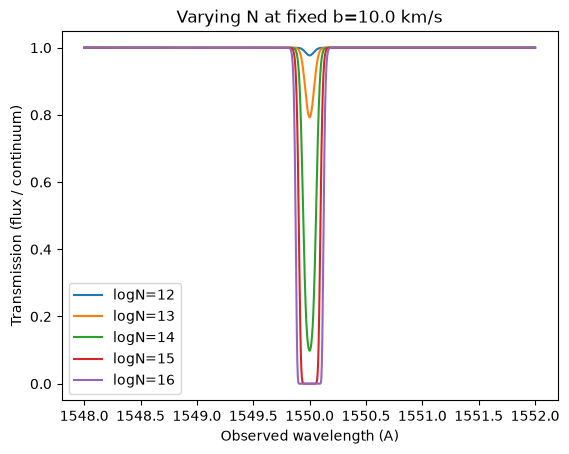

In [2]:
b_fixed = 10.0  # km/s
for logN in [12, 13, 14, 15, 16]:
    tau = optical_depth_gaussian(wave, line, logN=logN, b=b_fixed, z=z)
    plt.plot(wave, np.exp(-tau), label=f"logN={logN}")
plt.xlabel("Observed wavelength (A)")
plt.ylabel("Transmission (flux / continuum)")
plt.title(f"Varying N at fixed b={b_fixed} km/s")
plt.legend()
plt.show()

## Varying b at fixed N

Expect: higher b -> broader, shallower line, since the same amount
of gas (N) is spread over a wider velocity range.

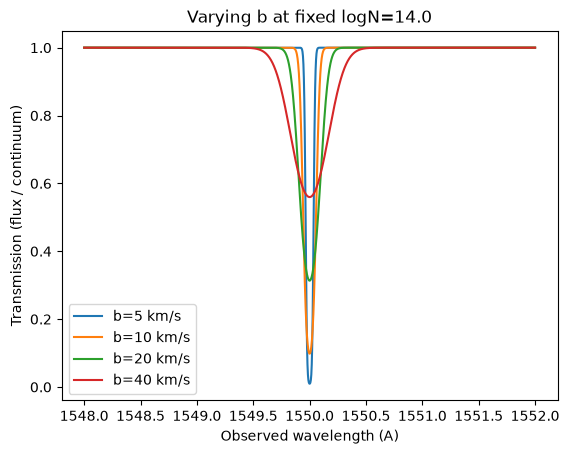

In [3]:
logN_fixed = 14.0
for b in [5, 10, 20, 40]:
    tau = optical_depth_gaussian(wave, line, logN=logN_fixed, b=b, z=z)
    plt.plot(wave, np.exp(-tau), label=f"b={b} km/s")
plt.xlabel("Observed wavelength (A)")
plt.ylabel("Transmission (flux / continuum)")
plt.title(f"Varying b at fixed logN={logN_fixed}")
plt.legend()
plt.show()

## Next step

Add the Lorentzian (damping, Gamma) term via `scipy.special.wofz` to
get the full Voigt profile, and compare its wings to this
Gaussian-only version for a saturated line (large N).